# 02. Deutsch and Deutsch–Jozsa algorithms
Given a function f that is promised to be either **constant** or **balanced**, one oracle query is enough to decide which. Measuring all-zeros means constant; anything else means balanced.

The notebook first builds the 1-bit Deutsch circuit with four oracles, then the n-bit Deutsch–Jozsa circuit.

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
sim = AerSimulator()

def run(qc, shots=1000):
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

## Deutsch (1 input bit)

In [2]:
def deutsch_oracle(kind):
    o = QuantumCircuit(2, name=kind)
    if kind == "constant_0": pass
    elif kind == "constant_1": o.x(1)
    elif kind == "balanced_identity": o.cx(0,1)          # f(x) = x
    elif kind == "balanced_not": o.x(0); o.cx(0,1); o.x(0)   # f(x) = not x
    return o

def deutsch(kind):
    qc = QuantumCircuit(2,1)
    qc.x(1); qc.h([0,1])
    qc.compose(deutsch_oracle(kind), inplace=True)
    qc.h(0); qc.measure(0,0)
    return qc

for kind in ["constant_0","constant_1","balanced_identity","balanced_not"]:
    counts = run(deutsch(kind))
    verdict = "constant" if max(counts, key=counts.get)=='0' else "balanced"
    print(f"{kind:18s} {counts}  ->  {verdict}")
print(deutsch("balanced_identity").draw())

constant_0         {'0': 1000}  ->  constant
constant_1         {'0': 1000}  ->  constant


balanced_identity  {'1': 1000}  ->  balanced
balanced_not       {'1': 1000}  ->  balanced
     ┌───┐          ┌───┐┌─┐
q_0: ┤ H ├───────■──┤ H ├┤M├
     ├───┤┌───┐┌─┴─┐└───┘└╥┘
q_1: ┤ X ├┤ H ├┤ X ├──────╫─
     └───┘└───┘└───┘      ║ 
c: 1/═════════════════════╩═
                          0 


## Deutsch–Jozsa (n input bits)
The balanced oracle here is the parity function $f(x)=x_0\oplus\dots\oplus x_{n-1}$ (a CNOT from every input qubit onto the ancilla), so the measured result is `1111` for n=4.

n=4, oracle=balanced  {'1111': 1000}  ->  balanced
n=5, oracle=constant  {'00000': 1000}  ->  constant


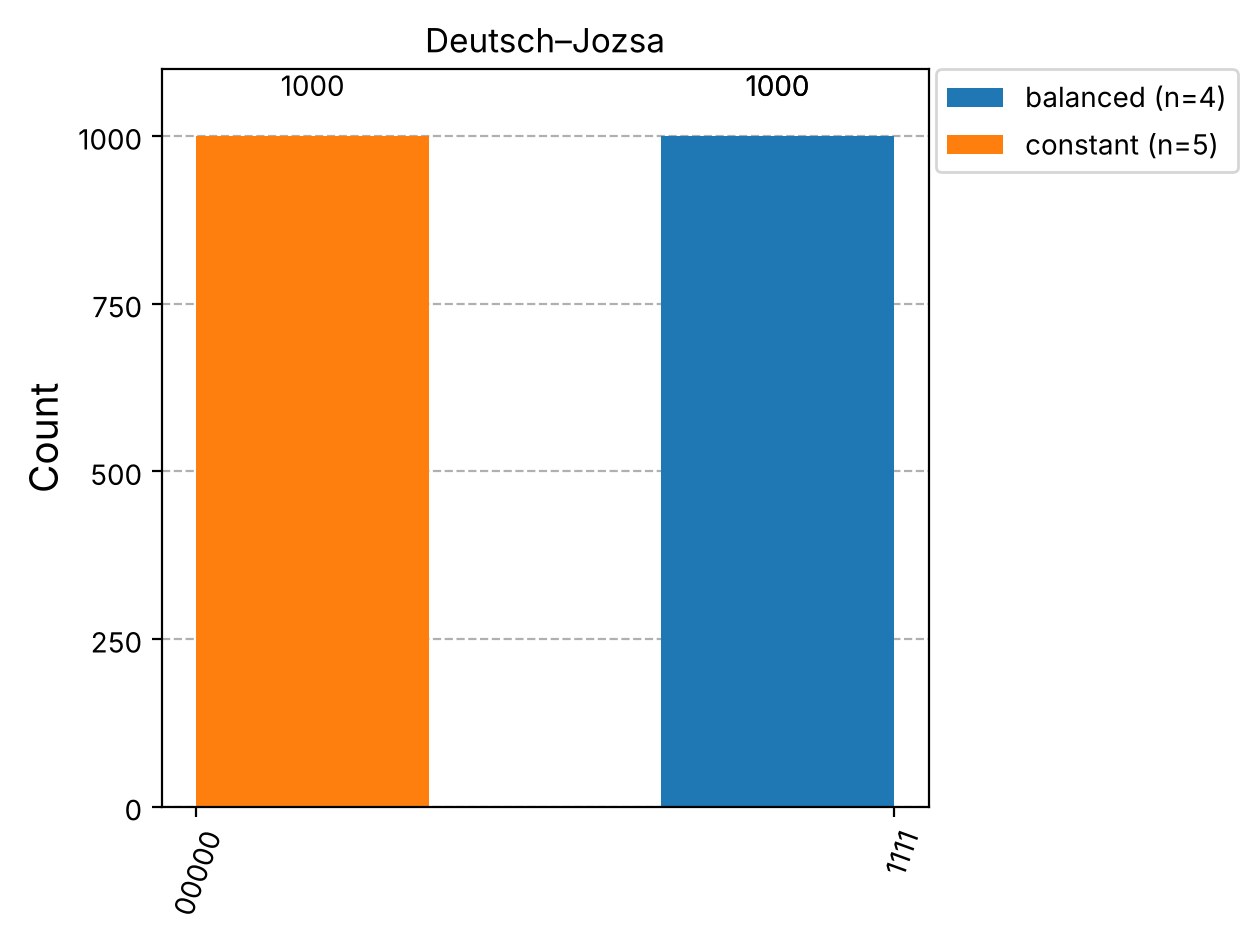

In [3]:
def dj_oracle(n, kind):
    o = QuantumCircuit(n+1, name=kind)
    if kind == "constant": o.x(n)
    else:
        for q in range(n): o.cx(q, n)
    return o

def deutsch_jozsa(n, kind):
    qc = QuantumCircuit(n+1, n)
    qc.x(n); qc.h(range(n+1))
    qc.compose(dj_oracle(n, kind), inplace=True)
    qc.h(range(n)); qc.measure(range(n), range(n))
    return qc

results = {}
for n, kind in [(4,"balanced"), (5,"constant")]:
    counts = run(deutsch_jozsa(n, kind))
    top = max(counts, key=counts.get)
    verdict = "constant" if top == '0'*n else "balanced"
    results[f"{kind} (n={n})"] = counts
    print(f"n={n}, oracle={kind:9s} {counts}  ->  {verdict}")
plot_histogram(list(results.values()), legend=list(results), title="Deutsch–Jozsa")